In [1]:
# --- Setup: make the project root importable ---
import sys
from pathlib import Path

# The notebook runs from notebooks/, so the project root is one level up
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, add_target
from src.config import TARGET_COL, FIGURES_DIR

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)  # make sure the folder exists

df = add_target(load_raw("por"))
print("Shape:", df.shape)
df.head()

Shape: (649, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,fail
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,0


In [2]:
# --- Class imbalance: counts and percentages ---
counts = df[TARGET_COL].value_counts().sort_index()          # 0 = pass, 1 = fail
pct = df[TARGET_COL].value_counts(normalize=True).sort_index() * 100

print(f"Pass (0): {counts[0]} students ({pct[0]:.1f}%)")
print(f"Fail (1): {counts[1]} students ({pct[1]:.1f}%)")

# A "dumb" model that always predicts the majority class (Pass)
baseline_acc = pct.max()
print(f"\nAlways-predict-Pass accuracy: {baseline_acc:.1f}%")
print("→ Any model must clearly beat this, and accuracy alone can't show it.")

Pass (0): 549 students (84.6%)
Fail (1): 100 students (15.4%)

Always-predict-Pass accuracy: 84.6%
→ Any model must clearly beat this, and accuracy alone can't show it.


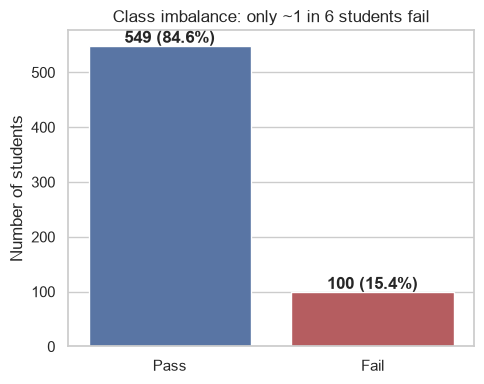

In [3]:
# --- Bar chart of the class balance ---
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Pass", "Fail"], y=counts.values, ax=ax,
            hue=["Pass", "Fail"], palette=["#4C72B0", "#C44E52"], legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")

ax.set_title("Class imbalance: only ~1 in 6 students fail")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_imbalance.png", dpi=150)
plt.show()

In [5]:
from src.config import GRADE_COLS

# All input features = everything except grades and the target
feature_cols = [c for c in df.columns if c not in GRADE_COLS + [TARGET_COL]]

num_cols = df[feature_cols].select_dtypes(include="number").columns.tolist()
cat_cols = df[feature_cols].select_dtypes(exclude="number").columns.tolist()

print(f"Features: {len(feature_cols)}  |  numeric: {len(num_cols)}  |  categorical: {len(cat_cols)}")
print("Numeric:    ", num_cols)
print("Categorical:", cat_cols)

Features: 30  |  numeric: 13  |  categorical: 17
Numeric:     ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


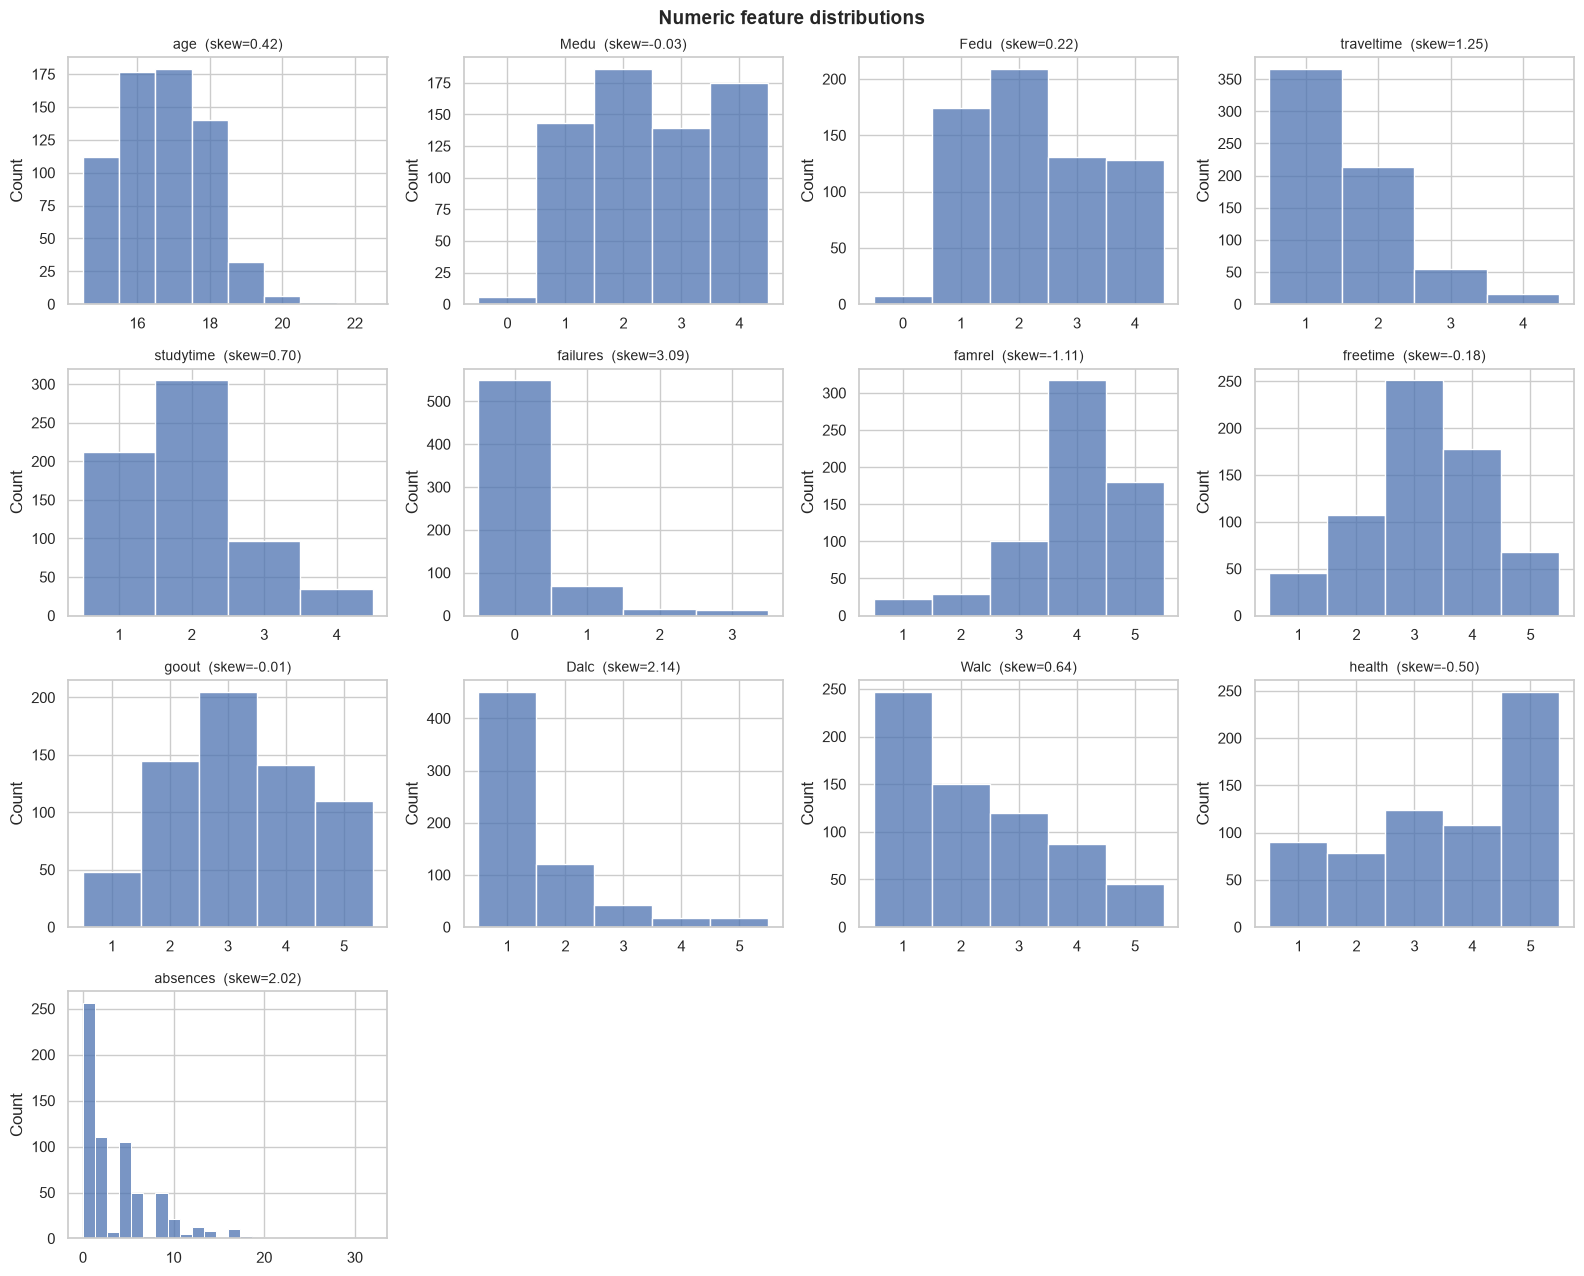

In [6]:
# One histogram per numeric feature, with skewness in the title
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.ravel()  # flatten the 4x4 grid into a simple list

for ax, col in zip(axes, num_cols):
    # discrete=True draws one bar per value for small integer scales
    sns.histplot(df[col], ax=ax, discrete=df[col].nunique() <= 10, color="#4C72B0")
    ax.set_title(f"{col}  (skew={df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(num_cols):]:   # hide the unused empty subplots
    ax.set_visible(False)

fig.suptitle("Numeric feature distributions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

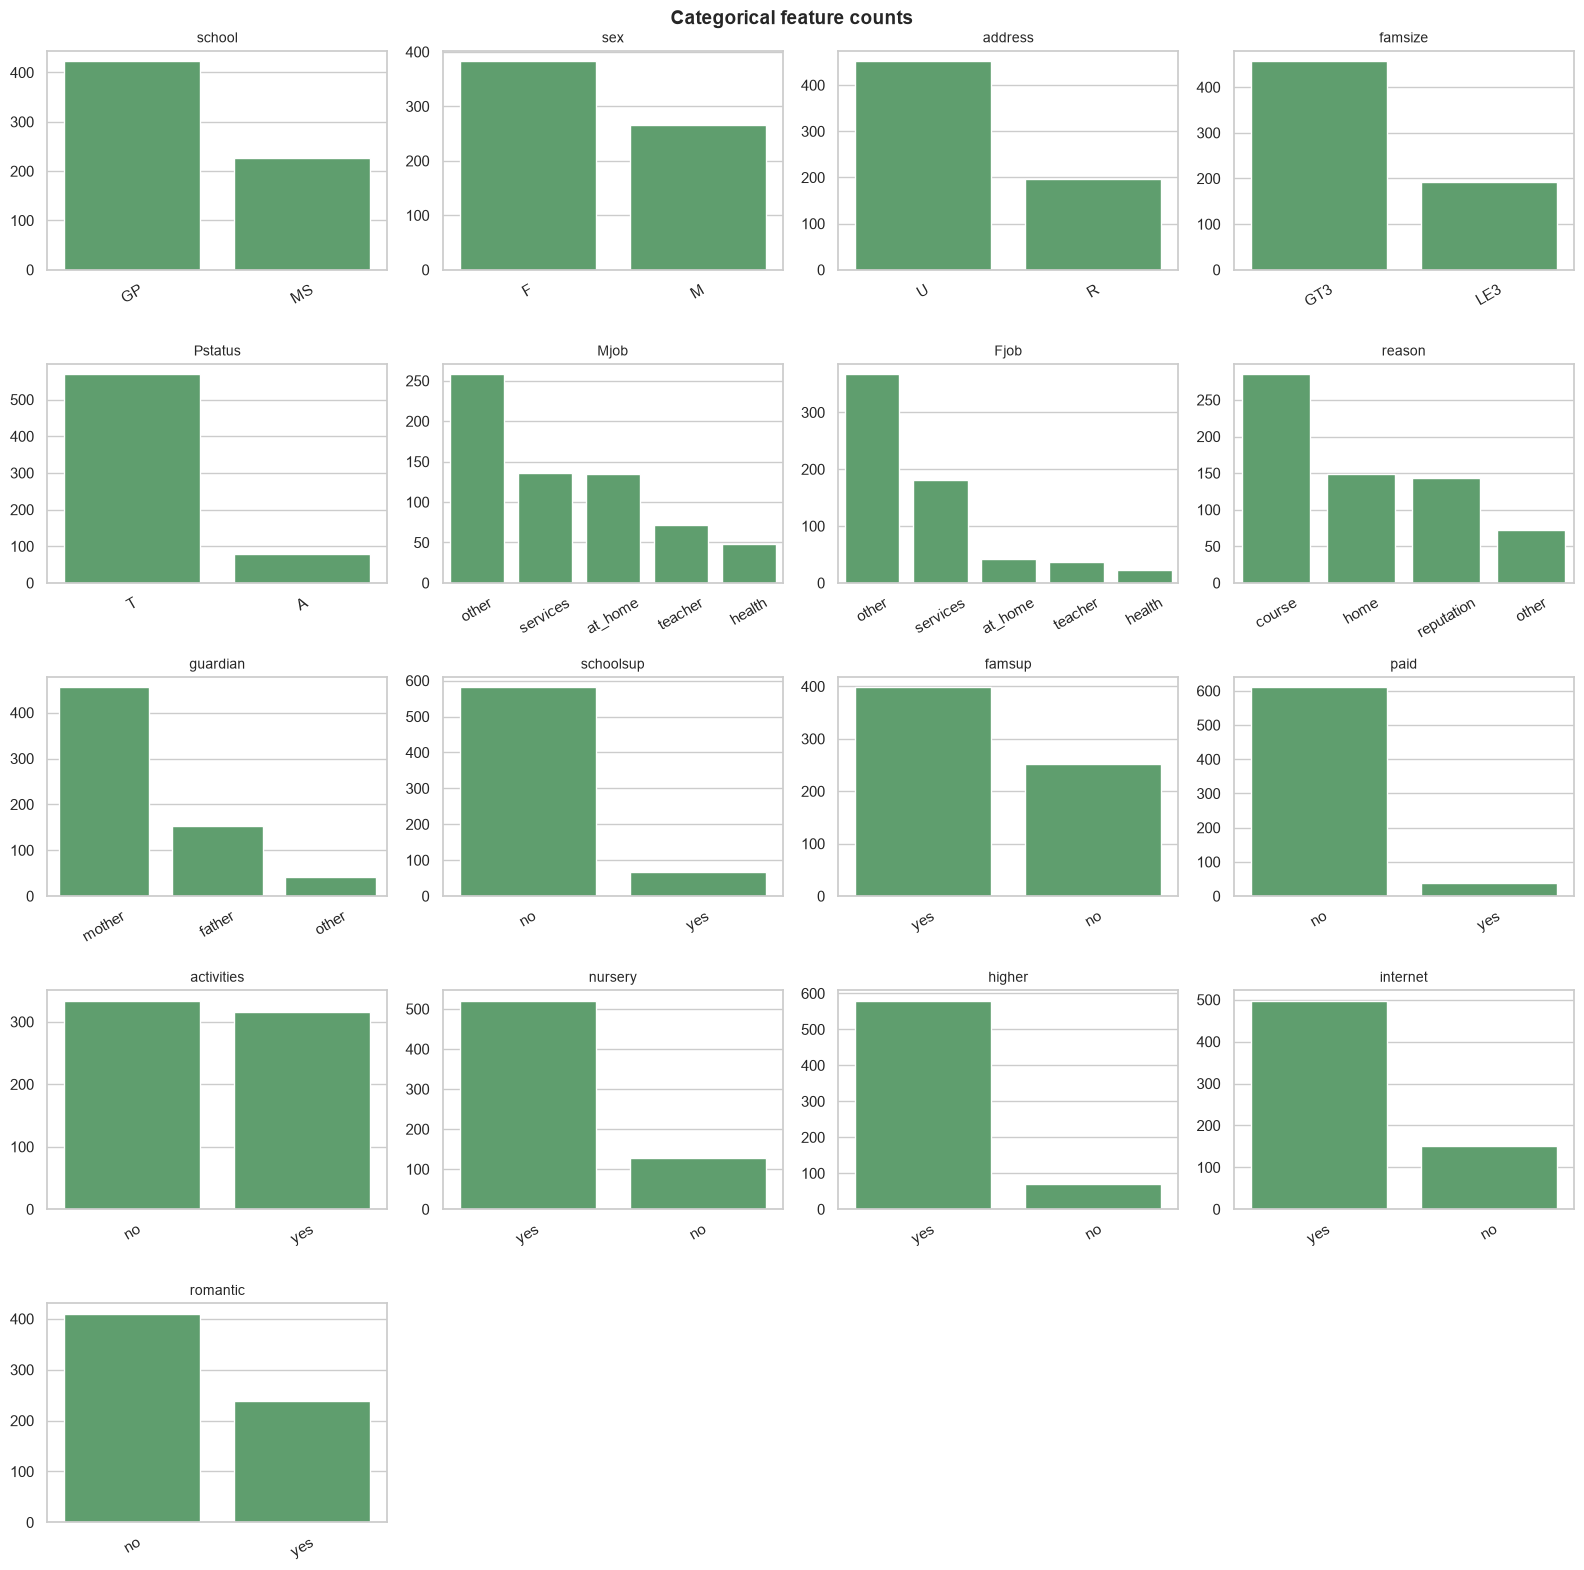

In [7]:
# One bar chart per categorical feature, most common value first
n = len(cat_cols)
ncols = 4
nrows = -(-n // ncols)  # ceiling division: enough rows for all charts

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(x=col, data=df, order=order, ax=ax, color="#55A868")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Categorical feature counts", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_categorical_counts.png", dpi=150)
plt.show()

In [8]:
# 1) Students with a final grade of exactly 0
zero_g3 = df[df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero_g3)} ({len(zero_g3) / len(df):.1%} of all)")
print("Their average G1 and G2:", zero_g3[["G1", "G2"]].mean().round(1).to_dict())

# 2) Absences: the typical student vs the extreme
print(f"\nAbsences: median = {df['absences'].median():.0f}, "
      f"mean = {df['absences'].mean():.1f}, max = {df['absences'].max()}")

Students with G3 = 0: 15 (2.3% of all)
Their average G1 and G2: {'G1': 7.1, 'G2': 3.8}

Absences: median = 2, mean = 3.7, max = 32
